# Import

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import sklearn
sklearn.set_config(transform_output="pandas") # Forces all transformers to output DataFrames!

# Data Loading & Splitting
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder

# Pipelines and Transformers
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

# Modeling & Evaluation
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

import seaborn as sns

import matplotlib.pyplot as plt

import math

# Merging and creating new columns

In [2]:
product_df = pd.read_csv('olist_products_dataset.csv')

product_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [3]:
product_df.shape

(32951, 9)

In [4]:
product_df.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [5]:
# Removed: weight and volume are not used for prediction.

In [6]:
# Removed: weight and volume are not used for prediction.

In [7]:
items_df = pd.read_csv('olist_order_items_dataset.csv')

items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
items_df.shape

(112650, 7)

In [9]:
items_df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [10]:
items_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
18470,2a6f4c120a863a097e15830fd31b820a,1,5a47c5b5c3866f29177d497727f22f38,218d46b86c1881d022bce9c68a7d4b15,2018-01-15 16:09:03,128.56,13.92
23521,35a3d210c364e3747478f468b0547bb2,1,52a646aa308987e28c375b41081de428,430315b7bb4b6e4b3c978f9dfa9b0558,2018-05-02 18:10:04,29.00,18.23
49432,705aedb629707ccd89c4fef86e25b2f3,1,177d3d5bb9d4d29222a222e3b3554f41,3d871de0142ce09b7081e2b9d1733cb1,2018-03-29 22:50:30,129.00,13.94
81967,ba4ca0fc7fbb88ea289868764ca06619,1,d443be168a577afdf50d59932d3b78c7,e9bc59e7b60fc3063eb2290deda4cced,2018-03-08 13:30:37,125.99,27.42
42612,610b8837e9399ae8047a7050cedb03d1,1,d22751a68b1be27e8cc1e6e328ffbc39,ea8482cd71df3c1969d7b9473ff13abc,2018-04-17 11:10:42,27.99,18.23


In [11]:
items_df.shape

(112650, 7)

In [12]:
merged_df = items_df.merge(product_df, on='product_id', how='left')

In [13]:
merged_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [14]:
merged_df.shape

(112650, 15)

In [15]:
merged_df['order_total_fv'] = items_df.groupby('order_id')['freight_value'].transform('sum')

In [16]:
merged_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,order_total_fv
49148,6fa75611a64dc552025fc1c48cc75cf4,1,febdb23f0a5a9f93c101e489d2bfd352,d97df38225e5abadaff1e72cb72b823c,2018-03-19 13:30:28,70.00,15.37,automotivo,55.0,327.0,1.0,150.0,16.0,8.0,11.0,15.37
84003,bedae8df4e37a65ccbec319872296b89,1,802d4aa654f6b24ca4d5bd2c61c0b079,6288c69c4ce638e59925e59193f98b16,2017-03-27 13:08:11,415.99,17.08,eletronicos,57.0,911.0,3.0,1350.0,33.0,25.0,30.0,17.08
65362,9562a9a598a619a1726397eb5246e623,1,c4ee4437696f1885d323b41852fedc8c,dfa0c4c6229ab200a4a1336b4d7128ff,2018-06-15 16:02:12,26.40,15.29,utilidades_domesticas,57.0,534.0,5.0,300.0,30.0,11.0,18.0,15.29
64544,937b8c2c23c033f63b1b46e876b2c385,2,f5889057b0c061390ce20f4b7b842ac0,daf565f087a52def0fd5c5825b3661bc,2018-07-04 09:10:32,49.90,39.31,cama_mesa_banho,59.0,392.0,1.0,1100.0,25.0,20.0,20.0,78.62
16453,25a36e7aae91280c6b8a389ba7585046,1,36c2fb4fa746273709c373f6d6ec6796,00ee68308b45bc5e2660cd833c3f81cc,2018-01-11 01:27:56,70.00,16.74,cama_mesa_banho,55.0,1714.0,1.0,6038.0,68.0,17.0,47.0,16.74


In [17]:
distances_df = pd.read_csv('distances.csv')

In [18]:
distances_df.head()

,Unnamed: 0,order_id,customer_id,customer_zip,seller_zip,customer_latitude,customer_longitude,seller_latitude,seller_longitude,distance
0,0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,3149,9350,-23.576983,-46.587161,-23.680729,-46.444238,18.660666
1,1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,47813,31570,-12.177924,-44.660711,-19.807681,-43.980427,855.370968
2,2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,75265,14840,-16.745150,-48.514783,-21.363502,-48.229601,516.752200
3,3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,59296,31842,-5.774190,-35.271143,-19.837682,-43.924053,1830.520884
4,4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,9195,8752,-23.676370,-46.514627,-23.543395,-46.262086,29.811709


In [19]:
merge_2_df = merged_df.merge(distances_df, on='order_id', how='left')

In [20]:
days_df = pd.read_csv('delivered_orders_with_actual_days.csv')

days_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,actual_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8,9.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9,10.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13,14.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2,3.0


In [21]:
days_df.shape

(96470, 10)

In [22]:
days_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_days', 'actual_delivery_days'],
      dtype='str')

In [23]:
combined_df = merge_2_df.merge(days_df, on='order_id', how='left')

In [24]:
combined_df.shape

(112650, 34)

In [25]:
combined_df['N_items'] = combined_df.groupby('order_id')['order_item_id'].transform('count')

In [26]:
# Removed: weight and volume are not used for prediction.

In [27]:
# Removed: weight and volume are not used for prediction.

In [28]:
combined_df['order_total_price'] = combined_df.groupby('order_id')['price'].transform('sum')

In [29]:
combined_df['order_categories'] = (
    combined_df.groupby('order_id')['product_category_name']
    .transform(lambda x: ', '.join(x.dropna().astype(str)))
)

In [30]:
combined_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,...,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,actual_delivery_days,N_items,order_total_price,order_categories
106396,f1cd9d30a289847f9a18900d191a4f05,1,0c877471e35049402bca235e06cb8063,dd7ddc04e1b6c2c614352b383efe2d36,2017-06-08 19:05:14,84.90,13.61,NaN,NaN,NaN,...,2017-06-04 18:58:07,2017-06-04 19:05:14,2017-06-06 18:21:40,2017-06-12 13:41:41,2017-06-28,7.0,8.0,2,169.80,
52909,7869f99f3acbb8cf623402053f1dddfb,1,9b6537fef0e6b345c644e019dbe8ac1b,270297ead4c65a6cd2593960d2af6b21,2018-03-05 18:48:18,78.00,8.74,casa_construcao,59.0,1251.0,...,2018-02-27 18:29:30,2018-02-27 18:48:18,2018-03-01 21:46:15,2018-03-02 21:58:30,2018-03-13,3.0,4.0,1,78.00,casa_construcao
41220,5de49d2694e14cb7d84e7131475e63b1,1,ab1ecbce7afd9f6e661baa24a5706c9c,d12c926d74ceff0a90a21184466ce161,2018-01-12 15:27:21,44.90,14.10,perfumaria,23.0,439.0,...,2018-01-07 15:18:02,2018-01-07 15:27:21,2018-01-08 20:01:42,2018-01-13 02:33:14,2018-02-02,5.0,6.0,2,89.80,"perfumaria, perfumaria"
71345,a2bbb88a8a7ebfa655f9172b60fd987f,1,fbc1488c1a1e72ba175f53ab29a248e8,058fd0aa2bfdb2274e05e1ae971dabb6,2017-12-07 17:12:32,118.00,14.58,perfumaria,27.0,311.0,...,2017-12-03 17:04:39,2017-12-03 17:12:32,2017-12-05 19:03:52,2017-12-16 12:47:57,2017-12-28,12.0,13.0,1,118.00,perfumaria
16351,257045bb76e4c622aa9767a99ee56fc6,1,6a23c2eb9acc78f8ec403be9c6210dd4,7c67e1448b00f6e969d365cea6b010ab,2017-07-26 03:25:47,119.94,20.81,moveis_escritorio,54.0,1094.0,...,2017-07-13 22:23:04,2017-07-15 03:34:23,2017-07-25 19:14:24,2017-08-07 17:12:49,2017-08-08,24.0,24.0,1,119.94,moveis_escritorio


In [31]:
combined_df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'order_total_fv', 'Unnamed: 0', 'customer_id_x', 'customer_zip',
       'seller_zip', 'customer_latitude', 'customer_longitude',
       'seller_latitude', 'seller_longitude', 'distance', 'customer_id_y',
       'order_status', 'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'delivery_days',
       'actual_delivery_days', 'N_items', 'order_total_price',
       'order_categories'],
      dtype='str')

In [32]:
cols_to_keep = [
    'order_id', 'order_total_fv', 'order_approved_at',
    'actual_delivery_days', 'N_items', 'distance',
    'customer_zip', 'seller_zip'
]
main_df = combined_df[cols_to_keep].copy()

In [33]:
main_df

,order_id,order_total_fv,order_approved_at,actual_delivery_days,N_items,distance,customer_zip,seller_zip
0,00010242fe8c5a6d1ba2dd792cb16214,13.29,2017-09-13 09:45:35,8.0,1,302.877093,28013,27277
1,00018f77f2f0320c557190d7a144bdd3,19.93,2017-04-26 11:05:13,17.0,1,588.229351,15775,3471
2,000229ec398224ef6ca0657da4fc703e,17.87,2018-01-14 14:48:30,8.0,1,313.765260,35661,37564
3,00024acbcdf0a6daa1e931b038114c75,12.79,2018-08-08 10:10:18,7.0,1,294.502886,12952,14403
4,00042b26cf59d7ce69dfabb4e55b4fd9,18.14,2017-02-04 14:10:13,26.0,1,649.104718,13226,87900
...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,43.41,2018-04-25 04:11:01,16.0,1,2767.076022,65077,88303
112646,fffcd46ef2263f404302a634eb57f7eb,36.53,2018-07-17 04:31:48,7.0,1,353.330448,81690,1206
112647,fffce4705a9662cd70adb13d4a31832d,16.95,2017-10-24 17:14:25,4.0,1,340.600306,4039,80610
112648,fffe18544ffabc95dfada21779c9644f,8.72,2017-08-15 00:04:32,2.0,1,72.665263,13289,4733


In [34]:
main_df['order_approved_at'] = pd.to_datetime(main_df['order_approved_at']).dt.normalize()

# EDA

In [35]:
main_df.isnull().sum()

order_id                   0
order_total_fv             0
order_approved_at       2476
actual_delivery_days    2476
N_items                    0
distance                 554
customer_zip               0
seller_zip                 0
dtype: int64

In [36]:
main_df.dropna(inplace=True)

In [37]:
main_df.isnull().sum()

order_id                0
order_total_fv          0
order_approved_at       0
actual_delivery_days    0
N_items                 0
distance                0
customer_zip            0
seller_zip              0
dtype: int64

In [38]:
main_df = main_df.sort_values('distance', ascending=False).drop_duplicates(subset='order_id', keep='first')

In [39]:
main_df.shape

(95978, 8)

In [40]:
main_df.dtypes

order_id                           str
order_total_fv                 float64
order_approved_at       datetime64[us]
actual_delivery_days           float64
N_items                          int64
distance                       float64
customer_zip                     int64
seller_zip                       int64
dtype: object

In [41]:
main_df.describe()

,order_total_fv,order_approved_at,actual_delivery_days,N_items,distance,customer_zip,seller_zip
count,95978.000000,95978,95978.000000,95978.000000,95978.000000,95978.000000,95978.000000
mean,22.779331,2018-01-01 21:33:15.082206,12.633166,1.142324,603.484028,35116.958793,24661.434693
min,0.000000,2016-09-15 00:00:00,-6.000000,1.000000,0.000000,1003.000000,1001.000000
25%,13.830000,2017-09-14 00:00:00,7.000000,1.000000,186.754629,11320.000000,6440.000000
50%,17.160000,2018-01-22 00:00:00,10.000000,1.000000,435.853527,24360.000000,13568.000000
75%,24.000000,2018-05-06 00:00:00,16.000000,1.000000,802.247773,58682.500000,29156.000000
max,1794.960000,2018-08-29 00:00:00,209.000000,21.000000,8717.412397,99980.000000,99730.000000
std,21.583233,NaN,9.518727,0.539353,596.396463,29826.528811,27738.564517


In [42]:
main_df = main_df[main_df['actual_delivery_days']>0]

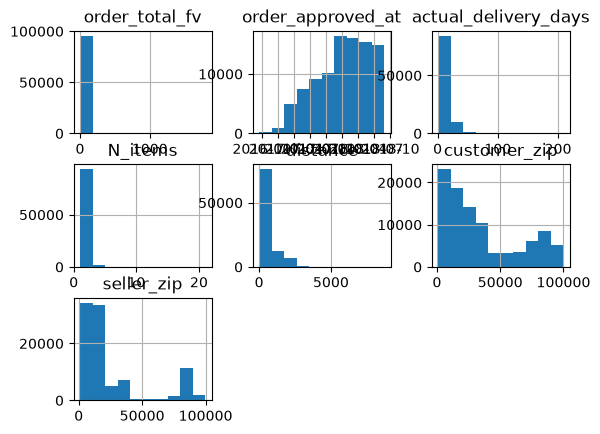

In [43]:
main_df.hist();

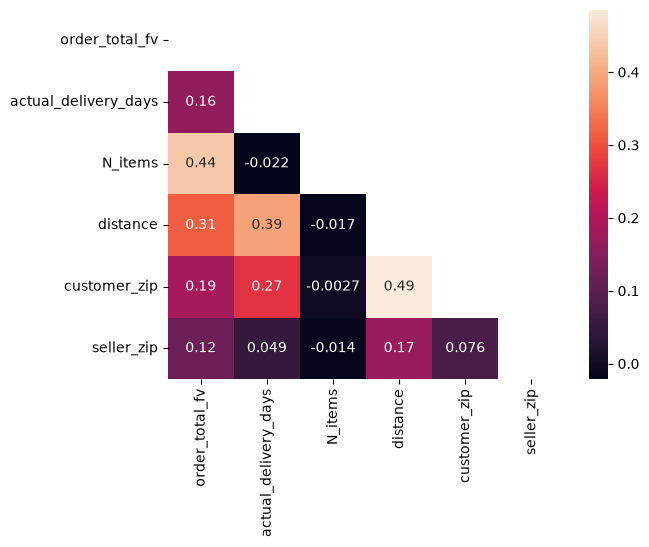

In [44]:
corr_matrix = main_df.corr(numeric_only=True)

mask = np.tril(np.ones_like(corr_matrix, dtype=bool), k=-1)

sns.heatmap(corr_matrix, mask=~mask, annot=True);

In [45]:
corr_matrix['actual_delivery_days'].abs().sort_values(ascending=False)

actual_delivery_days    1.000000
distance                0.391648
customer_zip            0.268537
order_total_fv          0.163959
seller_zip              0.048679
N_items                 0.021506
Name: actual_delivery_days, dtype: float64

In [46]:
main_df['customer_zip'] = main_df['customer_zip'].astype(str)
main_df['seller_zip'] = main_df['seller_zip'].astype(str)

In [47]:
main_df.to_csv('main_df.csv', index=False)

# Splitting

In [48]:
train_val, test = train_test_split(main_df, test_size=0.2, random_state=42)

train, val = train_test_split(train_val, test_size=0.2, random_state=42)

X_train = train.drop(columns='actual_delivery_days')
y_train = train['actual_delivery_days']

X_val = val.drop(columns='actual_delivery_days')
y_val = val['actual_delivery_days']

X_test = test.drop(columns='actual_delivery_days')
y_test = test['actual_delivery_days']

# Preprocessing

In [49]:
main_df.columns

Index(['order_id', 'order_total_fv', 'order_approved_at',
       'actual_delivery_days', 'N_items', 'distance', 'customer_zip',
       'seller_zip'],
      dtype='str')

In [50]:
def extract_date_features(X):
    result = pd.DataFrame(index=X.index)

    for col in X.columns:
        dates = pd.to_datetime(X[col])

        result[f'{col}_month'] = dates.dt.month
        result[f'{col}_day'] = dates.dt.day
        result[f'{col}_weekday'] = dates.dt.dayofweek
        result[f'{col}_is_weekend'] = (dates.dt.dayofweek >= 5).astype(int)

    return result

In [51]:
num_median_cols = ['order_total_fv', 'N_items', 'distance']
zip_cols = ['customer_zip', 'seller_zip']
date_cols = ['order_approved_at']

In [52]:
median_pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())

BRANCH_1 = ("num",median_pipe, num_median_cols)

In [53]:
zip_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))

BRANCH_2 = ("zip",zip_pipe, zip_cols)

In [54]:
date_pipe = make_pipeline(FunctionTransformer(extract_date_features, validate=False))

BRANCH_4 = ('date', date_pipe, date_cols)

In [55]:
ct = ColumnTransformer([BRANCH_1,
                        BRANCH_2,
                        BRANCH_4
                       ])

# Model

## Random Forest

In [56]:
rf_clf = RandomForestRegressor(n_estimators=300, max_samples=0.8, bootstrap=True, random_state=42)

rf_pipe = make_pipeline(ct,rf_clf)

rf_pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('zip', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [57]:
y_train_pred = rf_pipe.predict(X_train)

mean_absolute_error(y_train, y_train_pred)

2.199740103477397

In [58]:
y_val_pred = rf_pipe.predict(X_val)

mean_absolute_error(y_val, y_val_pred)

4.849366355574035

In [59]:
y_test_pred = rf_pipe.predict(X_test)

mean_absolute_error(y_test, y_test_pred)

4.92773625583875

## HGBR

In [60]:
hgbr = HistGradientBoostingRegressor(loss='absolute_error', learning_rate=0.05, max_iter=300,
    max_leaf_nodes=31, min_samples_leaf=30,
    categorical_features=[7, 8], random_state=42)

histgrad_pipe = make_pipeline(ct,hgbr)

histgrad_pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('zip', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outpu

In [61]:
y_pred_train = histgrad_pipe.predict(X_train)

mean_absolute_error(y_train,y_pred_train)

4.424224949169084

In [62]:
r2_score(y_train,y_pred_train)

0.28685899448356356

In [63]:
y_pred_val = histgrad_pipe.predict(X_val)

mean_absolute_error(y_val,y_pred_val)

4.522618020301363

In [64]:
y_pred_test = histgrad_pipe.predict(X_test)

mean_absolute_error(y_test,y_pred_test)

4.557291170534937

# Customer input

In [65]:
# Load the two lookup files you uploaded
geo_df = pd.read_csv('olist_geolocation_dataset.csv')
sellers_df = pd.read_csv('olist_sellers_dataset.csv')

# Use one representative latitude and longitude per ZIP code
zip_locations = geo_df.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].median()

# Find seller information by seller ID
sellers_by_id = sellers_df.set_index('seller_id')

print('Location and seller data loaded!')

Location and seller data loaded!


In [66]:
# Enter your order details here
customer_zip = '28013'
seller_id = '3442f8959a84dea7ee197c632cb2df15'
freight_cost = 13.29
number_of_items = 1
approval_date = '2017-09-13'

In [67]:
# Calculate distance and predict delivery time
from math import radians, sin, cos, sqrt, atan2

# ZIP codes in these files are five-digit Brazilian prefixes
customer_zip_number = int(str(customer_zip).strip())

if seller_id not in sellers_by_id.index:
    raise ValueError('Seller ID not found in olist_sellers_dataset.csv')

seller_zip_number = int(sellers_by_id.loc[seller_id, 'seller_zip_code_prefix'])

if customer_zip_number not in zip_locations.index:
    raise ValueError('Customer ZIP code not found in geolocation data')
if seller_zip_number not in zip_locations.index:
    raise ValueError('Seller ZIP code not found in geolocation data')

customer_lat, customer_lng = zip_locations.loc[customer_zip_number]
seller_lat, seller_lng = zip_locations.loc[seller_zip_number]

# Haversine formula: approximate straight-line distance (km)
lat1, lon1 = radians(customer_lat), radians(customer_lng)
lat2, lon2 = radians(seller_lat), radians(seller_lng)
a = sin((lat2-lat1)/2)**2 + cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2
distance_km = 6371 * 2 * atan2(sqrt(a), sqrt(1-a))

# One row with the same feature names used to train the model
new_order = pd.DataFrame([{
    'order_total_fv': freight_cost,
    'order_approved_at': pd.to_datetime(approval_date),
    'N_items': number_of_items,
    'distance': distance_km,
    'customer_zip': str(customer_zip_number),
    'seller_zip': str(seller_zip_number)
}])

predicted_days = float(histgrad_pipe.predict(new_order)[0])
predicted_days = max(0, predicted_days)  # Delivery time cannot be negative
arrival_date = pd.to_datetime(approval_date) + pd.Timedelta(days=round(predicted_days))

print('Seller ZIP:', str(seller_zip_number).zfill(5))
print(f'Approximate distance: {distance_km:.1f} km')
print(f'Predicted delivery time: {math.ceil(predicted_days)} days')
print('Estimated delivery date:', arrival_date.strftime('%Y-%m-%d'))

Seller ZIP: 13023
Approximate distance: 604.8 km
Predicted delivery time: 12 days
Estimated delivery date: 2017-09-25
